# NMS propio, cabeza de pertenencia y union del pipeline

**Entradas:** `splits/dataset.csv`, el manifiesto de cortes positivos, las definiciones de los notebooks `Ventaneo_hu`, `Targets_deteccion`, `Backbone` y `Segmentacion_instancias`, los modulos `deteccion_grid.py`, `cbam_modulos.py`, `pertenencia.py`, `pipeline_pengwin.py`, `evidencias_nms.py` y el checkpoint de Entrenamiento_multitarea en `resultados/modelos/entrenamiento_multitarea/`.

**Salidas:** `resultados/metricas/nms_pertenencia/`, `resultados/figuras/nms_pertenencia/` y `resultados/modelos/nms_pertenencia/cabeza_pertenencia.pt`.

Este notebook conecta las piezas de semana 10 que me corresponden, sobre el modelo multitarea entrenado por Miguel:

1. **NMS propio por clase** (`deteccion_grid.nms_por_clase`): filtra cajas duplicadas de la cabeza grid.
2. **Cabeza de pertenencia** (`pertenencia.PertenenciaHead`): tercera cabeza sobre el backbone compartido; asigna cada fragmento a sacro, coxal izquierdo o coxal derecho. Se entrena en una **etapa D** con el tronco de Miguel congelado.
3. **Unión detección → NMS → segmentación → pertenencia** (`pipeline_pengwin.py`), con salidas vacías probadas.

Pruebas automáticas: `python -m unittest tests.test_nms tests.test_pertenencia tests.test_pipeline -v`.

> Si el checkpoint de Miguel no está en `resultados/modelos/entrenamiento_multitarea/`, el notebook corre con pesos **sin entrenar** y lo dice en cada resultado: en ese caso demuestra que el sistema está conectado, no su desempeño.

## 1. Configuracion

Rutas relativas a la raiz del repositorio y lectura de los archivos que generan los notebooks anteriores. Las definiciones compartidas se cargan por nombre desde el notebook donde viven (`definiciones_notebooks.cargar_definiciones`), sin ejecutar sus celdas de prueba.

In [1]:
from pathlib import Path
import gc
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import SimpleITK as sitk
import torch
import torch.nn as nn
import torch.nn.functional as F   # lo usan SkipFusionBlock y CenterOffsetSkipDecoder (se cargan sin sus imports)
from PIL import Image             # lo usa restore_letterbox_label_mask (volumen completo)

# Raiz del repositorio: funciona si el kernel arranca en notebooks/ o en la raiz.
BASE_DIR = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").is_file())
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))  # para importar los modulos de src/

from src.definiciones_notebooks import cargar_definiciones

SPLITS_DIR = BASE_DIR / "splits"
from src.rutas import FIGURAS_DIR, MANIFEST_CSV, METRICAS_DIR, MODELOS_DIR
NOTEBOOKS_DIR = BASE_DIR / "notebooks"

def to_repo_relative(path):
    """Guarda rutas portables dentro del repositorio."""
    path = Path(path)
    try:
        return path.relative_to(BASE_DIR).as_posix()
    except ValueError:
        return path.as_posix()


def resolve_repo_path(path):
    """Permite leer rutas relativas o absolutas sin romper compatibilidad."""
    path = Path(path)
    if path.is_absolute():
        return path
    return BASE_DIR / path

# Dataset curado y splits generados por Dataset_splits.ipynb
df = pd.read_csv(SPLITS_DIR / "dataset.csv", dtype={"case_id": str})
# Indice de cortes positivos generado por Targets_deteccion.ipynb
slice_manifest = pd.read_csv(MANIFEST_CSV, dtype={"case_id": str})

cargar_definiciones(NOTEBOOKS_DIR / "Ventaneo_hu.ipynb", {"load_mha", "apply_hu_window", "enhance_bone_contrast"}, destino=globals())
cargar_definiciones(NOTEBOOKS_DIR / "Targets_deteccion.ipynb", {"instance_to_semantic", "boxes_from_semantic", "letterbox_pair", "build_detection_target",
     "PengwinDetectionDataset", "detection_collate"},
                    valores={"CLASS_ID_TO_NAME", "TARGET_COLORS"}, destino=globals())
cargar_definiciones(NOTEBOOKS_DIR / "Backbone.ipynb", {"FundidoraPC", "FundidoraPCPlus", "build_backbone", "theoretical_receptive_field",
     "count_parameters", "make_models"}, destino=globals())
cargar_definiciones(NOTEBOOKS_DIR / "Segmentacion_instancias.ipynb",
                    {"backbone_feature_pyramid", "build_detection_region_priors", "SegmentationConvBlock",
                     "SkipFusionBlock", "CenterOffsetSkipDecoder", "decode_center_offset_instances",
                     "restore_letterbox_label_mask", "link_slice_instances_to_volume"}, destino=globals())

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| dispositivo:", DEVICE)

torch 2.14.1+cpu | dispositivo: cpu


In [2]:
import ast
import json
import subprocess
import time

from src.deteccion_grid import NMS_CONFIG, GridDetectionHead, decode_predictions, nms_por_clase, postprocess
from src.cbam_modulos import CBAM, CompuertaResidualCBAM
from src.pertenencia import (PertenenciaHead, cargar_submodulo, entrenar_pertenencia, perdida_pertenencia,
                         precalcular_cache_pertenencia, predecir_cache, targets_pertenencia, metricas_pertenencia)
from src.pipeline_pengwin import (CONFIG_PIPELINE, calibrar_umbral_corte, evaluar_pertenencia, inferir_cortes,
                              inferir_volumen, resumen_evaluacion_pertenencia, scores_por_corte)
from src.evidencias_nms import barrido_nms, figura_antes_despues, logits_oraculo

ENTRENAMIENTO_DIR = MODELOS_DIR / "entrenamiento_multitarea"     # pesos de Miguel
FABIAN_MODELOS_DIR = MODELOS_DIR / "nms_pertenencia"            # cabeza de pertenencia
FABIAN_METRICAS_DIR = METRICAS_DIR / "nms_pertenencia"          # tablas CSV
FABIAN_FIGURAS_DIR = FIGURAS_DIR / "nms_pertenencia"            # figuras PNG
for _d in (FABIAN_MODELOS_DIR, FABIAN_METRICAS_DIR, FABIAN_FIGURAS_DIR):
    _d.mkdir(parents=True, exist_ok=True)
print("Configuración del pipeline:", CONFIG_PIPELINE)

Configuración del pipeline: {'score_thresh': 0.05, 'iou_thresh': 0.5, 'max_det_per_class': 1, 'center_threshold': 0.25, 'min_center_distance': 7, 'min_instance_pixels': 1, 'output_size': (256, 256), 'umbral_corte': None}


## 2. Cargar el modelo multitarea entrenado (Miguel)

- Se busca `modelo_multitarea_final.pt` (exportado) o `best_C_conjunto.pth` (checkpoint de la etapa C) en `resultados/modelos/entrenamiento_multitarea/`. Los pesos vienen en el repositorio por **Git LFS**: si `git lfs pull` no se ha ejecutado, el archivo es un puntero de texto y la celda lo avisa.
- La arquitectura se lee del propio checkpoint (`architecture.use_skips` o `USE_SKIPS` de su configuración):
  - **Con skips (modelo actual):** decoder `CenterOffsetSkipDecoder` de Segmentacion_instancias y pirámide completa `backbone_feature_pyramid` (f1, f2, f3, f4), igual que `MultiTaskNet` en Entrenamiento_multitarea.
  - **Sin skips (checkpoints antiguos):** la definición de `CenterOffsetSegmentationDecoder` se recupera del commit registrado en el checkpoint (`git_commit`) y dos adaptadores la conectan al pipeline.
- La carga es estricta (`cargar_submodulo`): si sobra o falta una clave, falla en vez de cargar pesos a medias. Además se comprueba que la pirámide termine en el mismo `f4` que usa la cabeza de detección.

In [3]:
def recuperar_definicion_de_git(commit, archivo, nombre):
    """Ejecuta en este notebook la clase/función `nombre` tal como estaba en `archivo` en el `commit` dado."""
    texto = subprocess.run(["git", "show", f"{commit}:{archivo}"], cwd=BASE_DIR, capture_output=True,
                           text=True, encoding="utf-8", check=True).stdout
    for celda in json.loads(texto)["cells"]:
        if celda["cell_type"] != "code":
            continue
        fuente = "".join(celda["source"])
        try:
            arbol = ast.parse(fuente)
        except SyntaxError:
            continue
        for nodo in arbol.body:
            if getattr(nodo, "name", None) == nombre:
                exec(ast.get_source_segment(fuente, nodo), globals())
                return globals()[nombre]
    raise LookupError(f"{nombre} no está en {archivo} del commit {commit}")


class DecoderSinSkips(nn.Module):
    """Adaptador: el decoder de Miguel recibe solo f4; el pipeline le pasa (imagen, pirámide, priors)."""
    def __init__(self, decoder):
        super().__init__()
        self.decoder = decoder

    def forward(self, image, features, region_priors, output_size=(256, 256)):
        return self.decoder(features[-1], region_priors, output_size=output_size)


def features_backbone_miguel(backbone, x):
    """Adaptador: el backbone devuelve (pooled, f4); el pipeline espera una pirámide cuyo último nivel es f4."""
    return [None, None, None, backbone(x)[1]]


def preprocesar_corte(corte_hu, output_size=256):
    """Mismo preprocesamiento del dataset: ventaneo HU -> CLAHE -> letterbox. Devuelve (imagen 256x256, transform)."""
    imagen = enhance_bone_contrast(apply_hu_window(corte_hu))
    imagen_256, _, transform = letterbox_pair(imagen, np.zeros(corte_hu.shape, dtype=np.int16), output_size)
    return imagen_256, transform


MODELO_PATH = next((p for p in (ENTRENAMIENTO_DIR / "modelo_multitarea_final.pt",
                                ENTRENAMIENTO_DIR / "best_C_conjunto.pth") if p.is_file()), None)
PESOS_ENTRENADOS = DECODER_OK = False
comunes = {"priors_fn": build_detection_region_priors, "decode_fn": decode_center_offset_instances,
           "restore_fn": restore_letterbox_label_mask, "link_fn": link_slice_instances_to_volume,
           "preprocess_fn": preprocesar_corte}

if MODELO_PATH is not None and MODELO_PATH.stat().st_size < 10_000:
    raise RuntimeError(f"{MODELO_PATH.name} pesa {MODELO_PATH.stat().st_size} bytes: es un puntero de Git LFS, "
                       "no los pesos. Ejecuta `git lfs install` y `git lfs pull` en la raíz del repositorio.")

if MODELO_PATH is not None:
    try:
        payload = torch.load(MODELO_PATH, map_location="cpu", weights_only=True)
    except Exception:                       # checkpoint de entrenamiento: trae optimizador y config (archivo del equipo)
        payload = torch.load(MODELO_PATH, map_location="cpu", weights_only=False)
    sd = payload["model_state_dict"]
    cfg_entrenamiento = payload.get("training_config", payload.get("config", {}))
    arquitectura = payload.get("architecture", {})
    backbone_name = arquitectura.get("backbone_name", cfg_entrenamiento.get("BACKBONE_NAME", "plus"))
    usa_skips = bool(arquitectura.get("use_skips", cfg_entrenamiento.get("USE_SKIPS", False)))
    commit_entrenamiento = cfg_entrenamiento.get("git_commit", "0db074a")

    backbone_m = cargar_submodulo(build_backbone(backbone_name, in_channels=1), sd, "backbone.").to(DEVICE).eval()
    cbam_m = cargar_submodulo(CompuertaResidualCBAM(CBAM(256)), sd, "cbam.").to(DEVICE).eval()
    det_head_m = cargar_submodulo(GridDetectionHead(), sd, "det_head.").to(DEVICE).eval()
    PESOS_ENTRENADOS = True

    if usa_skips:
        # Modelo actual (USE_SKIPS = True): mismo decoder y misma pirámide que MultiTaskNet en Entrenamiento_multitarea.
        decoder_m = cargar_submodulo(CenterOffsetSkipDecoder(in_channels=256, image_channels=1, use_skips=True),
                                     sd, "seg_decoder.").to(DEVICE).eval()
        seg_decoder_pipeline, features_fn = decoder_m, backbone_feature_pyramid
        DECODER_OK = True
    else:
        # Checkpoint antiguo (sin skips): la definición se recupera del commit con el que se entrenó.
        try:
            DecoderEntrenado = recuperar_definicion_de_git(commit_entrenamiento, "proyecto_pengwin.ipynb",
                                                           "CenterOffsetSegmentationDecoder")
            decoder_m = cargar_submodulo(DecoderEntrenado(in_channels=256), sd, "seg_decoder.").to(DEVICE).eval()
            seg_decoder_pipeline, features_fn = DecoderSinSkips(decoder_m), features_backbone_miguel
            DECODER_OK = True
        except Exception as exc:
            seg_decoder_pipeline, features_fn = None, features_backbone_miguel
            print(f"AVISO: no se pudo reconstruir el decoder entrenado ({type(exc).__name__}: {exc}).")

    componentes = {"backbone": backbone_m, "cbam": cbam_m, "det_head": det_head_m,
                   "seg_decoder": seg_decoder_pipeline, "cls_head": None, "features_fn": features_fn, **comunes}

    # Contrato: la pirámide termina en el MISMO f4 que usa la cabeza de detección (igual que en el entrenamiento).
    with torch.no_grad():
        _x = torch.rand(2, 1, 256, 256, device=DEVICE)
        assert torch.allclose(features_fn(backbone_m, _x)[-1], backbone_m(_x)[1], atol=1e-5), \
            "la pirámide del backbone no coincide con f4"

    sel = payload.get("selected_from", {"stage": payload.get("stage"), "epoch": payload.get("epoch")})
    etapa = sel.get("stage")
    etapa = etapa.get("name") if isinstance(etapa, dict) else etapa
    print(f"Modelo de Miguel cargado desde {MODELO_PATH.name} | backbone '{backbone_name}' | "
          f"skips: {usa_skips} | commit {commit_entrenamiento[:7]} | etapa {etapa}, época {sel.get('epoch')}")
    print("Decoder entrenado:", "OK" if DECODER_OK else "NO disponible")
else:
    torch.manual_seed(SEED)
    backbone_sin_entrenar = build_backbone("base", in_channels=1).to(DEVICE).eval()
    torch.manual_seed(SEED)
    componentes = {"backbone": backbone_sin_entrenar, "cbam": CompuertaResidualCBAM(CBAM(256)).to(DEVICE),
                   "det_head": GridDetectionHead().to(DEVICE),
                   "seg_decoder": CenterOffsetSkipDecoder(in_channels=256, image_channels=1).to(DEVICE),
                   "cls_head": None, "features_fn": backbone_feature_pyramid, **comunes}
    DECODER_OK = True
    print("AVISO: no se encontró el checkpoint de Miguel en", ENTRENAMIENTO_DIR)
    print("       Se usan pesos SIN ENTRENAR: los resultados prueban el contrato, no el desempeño.")


@torch.no_grad()
def tronco(x):
    """Backbone + compuerta CBAM -> f4 [B,256,16,16] (el mapa compartido por las tres cabezas)."""
    f4 = componentes["features_fn"](componentes["backbone"], x)[-1]
    salida = componentes["cbam"](f4)
    return salida[0] if isinstance(salida, tuple) else salida

Modelo de Miguel cargado desde modelo_multitarea_final.pt | backbone 'plus' | skips: True | commit 680f514 | etapa C_conjunto, época 7
Decoder entrenado: OK


## 3. NMS propio por clase: antes y después

El detector grid propone una caja por celda; las celdas vecinas a un hueso proponen cajas casi iguales. El NMS conserva la de mayor score y elimina las de **la misma clase** con IoU > `iou_thresh`. Con `max_det_per_class = 1` queda como máximo una caja por región en cada corte, que es lo que define el target. Con esa configuración el NMS da **exactamente** las mismas cajas que el marcador provisional `predicted_boxes_top1` usado en el entrenamiento (prueba `NMSReemplazaAlMarcadorDeMiguel`), así que reemplazarlo no exige reentrenar.

Con el modelo entrenado, la tabla usa su salida real sobre `val`. Sin él, `logits_oraculo` simula la salida a partir de las cajas reales (prueba el mecanismo, no el desempeño). La configuración del NMS se elige con `val`; `test` no se usa aquí.

In [4]:
# --- Muestras compactas de val: solo lo que usa esta sección, máscaras en int16.
N_CORTES_VAL_NMS = 200


def muestra_compacta(ds, i):
    img, t = ds[i]
    return img, {"case_id": t["case_id"], "slice_index": t["slice_index"], "boxes": t["boxes"], "labels": t["labels"],
                 "instance_mask": t["instance_mask"].to(torch.int16), "instance_ids": t["instance_ids"]}


val_dataset_nms = PengwinDetectionDataset(split="val", as_torch=True)
indices_nms = sorted(set(np.linspace(0, len(val_dataset_nms) - 1,
                                     min(N_CORTES_VAL_NMS, len(val_dataset_nms))).astype(int).tolist()))
muestras_nms = [muestra_compacta(val_dataset_nms, i) for i in indices_nms]
val_dataset_nms._image = val_dataset_nms._label = None    # no retener el último volumen
imagenes_nms = [m[0] for m in muestras_nms]
targets_nms = [m[1] for m in muestras_nms]
del muestras_nms
gc.collect()
print(f"{len(targets_nms)} cortes de val (de {len(val_dataset_nms)}) | casos: {sorted({t['case_id'] for t in targets_nms})}")

<string>:42: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
<string>:47: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)


200 cortes de val (de 1265) | casos: ['035', '037', '067', '071', '079']


In [5]:
if PESOS_ENTRENADOS:
    with torch.no_grad():
        salida_det = torch.cat([componentes["det_head"](tronco(torch.stack(imagenes_nms[i:i + 32]).to(DEVICE))).float().cpu()
                                for i in range(0, len(imagenes_nms), 32)])
    origen_salida = "modelo entrenado (Miguel)"
else:
    salida_det = logits_oraculo(targets_nms, seed=SEED)
    origen_salida = "salidas simuladas (oráculo)"

tabla_nms = barrido_nms(salida_det, targets_nms, score_thresh=CONFIG_PIPELINE["score_thresh"])
tabla_nms.insert(0, "origen", origen_salida)
tabla_nms.to_csv(FABIAN_METRICAS_DIR / "barrido_nms_val.csv", index=False)
tabla_nms.round(3)

,origen,config,iou_thresh,max_det_per_class,ap50_sacro,ap50_coxal_izquierdo,ap50_coxal_derecho,map50,map50_95,iou_medio_tp,n_pred,tp50,fp50,fn50,cajas_por_corte
0,modelo entrenado (Miguel),sin NMS,NaN,-,0.780,0.918,0.945,0.881,0.619,0.860,845,474,371,37,4.225
1,modelo entrenado (Miguel),NMS,0.3,1,0.781,0.943,0.961,0.895,0.622,0.855,526,470,56,41,2.630
2,modelo entrenado (Miguel),NMS,0.4,1,0.781,0.943,0.961,0.895,0.622,0.855,526,470,56,41,2.630
3,modelo entrenado (Miguel),NMS,0.5,1,0.781,0.943,0.961,0.895,0.622,0.855,526,470,56,41,2.630
4,modelo entrenado (Miguel),NMS,0.6,1,0.781,0.943,0.961,0.895,0.622,0.855,526,470,56,41,2.630
5,modelo entrenado (Miguel),NMS,0.7,1,0.781,0.943,0.961,0.895,0.622,0.855,526,470,56,41,2.630
6,modelo entrenado (Miguel),NMS,0.3,sin tope,0.785,0.939,0.964,0.896,0.623,0.854,561,472,89,39,2.805
7,modelo entrenado (Miguel),NMS,0.4,sin tope,0.784,0.939,0.964,0.896,0.623,0.854,571,472,99,39,2.855
8,modelo entrenado (Miguel),NMS,0.5,sin tope,0.784,0.939,0.964,0.895,0.623,0.854,582,472,110,39,2.910
9,modelo entrenado (Miguel),NMS,0.6,sin tope,0.789,0.939,0.963,0.897,0.624,0.855,601,473,128,38,3.005


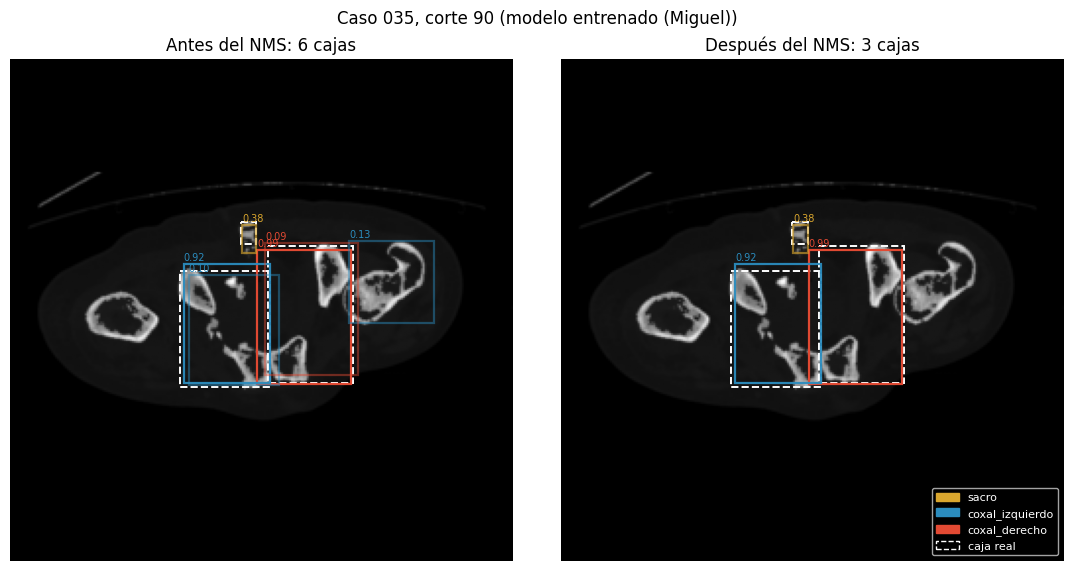

In [6]:
k = next((i for i, t in enumerate(targets_nms) if len(t["labels"]) == 3), 0)
raw_k = decode_predictions(salida_det[k:k + 1], score_thresh=CONFIG_PIPELINE["score_thresh"])[0]
final_k = postprocess(salida_det[k:k + 1], score_thresh=CONFIG_PIPELINE["score_thresh"],
                      nms_fn=nms_por_clase, **NMS_CONFIG)[0]
t = targets_nms[k]
figura_antes_despues(imagenes_nms[k], t, raw_k, final_k,
                     titulo=f"Caso {t['case_id']}, corte {t['slice_index']} ({origen_salida})",
                     path=FABIAN_FIGURAS_DIR / "nms_antes_despues.png")
plt.show()

**Cómo leer la tabla.** Sin NMS, los duplicados cuentan como falsos positivos (`fp50`) y bajan el mAP. Con `max_det_per_class = 1` el valor de `iou_thresh` no cambia el resultado: al conservar solo la mejor caja de cada clase, el umbral nunca llega a aplicarse. Sin tope por clase, el umbral sí importa. La configuración se elige comparando estas filas en `val`.

## 4. Cabeza de pertenencia: etapa D de entrenamiento

La tercera cabeza recibe el mapa compartido `f4` (después de la compuerta CBAM) y la máscara de cada fragmento: promedia `f4` dentro del fragmento, agrega 6 rasgos de posición y tamaño y un MLP da 3 logits. La posición es la pista principal para izquierdo/derecho: los coxales son casi simétricos.

**Etapa D.** Se congela el tronco entrenado (backbone + CBAM) y se entrena solo esta cabeza con las máscaras **reales** de `train` (teacher forcing), igual que la etapa B entrenó solo el decoder. Como el tronco no cambia, `f4` se calcula una vez por corte y cada época solo pasa por la cabeza: cabe en CPU. Pérdida: entropía cruzada con pesos inversos a la frecuencia de cada clase en `train`. Selección: mejor F1 macro en `val`, con parada temprana.

Unidad de clasificación: un fragmento en un corte. Advertencia para entrenamientos futuros: un flip horizontal intercambia izquierdo y derecho; si se usa como aumento, intercambiar también las etiquetas 2 ↔ 3.

**Cuándo se reentrena.** Junto a `cabeza_pertenencia.pt` se guarda `cabeza_pertenencia_meta.json` con la huella (SHA-256) del checkpoint del tronco. Si el checkpoint de Miguel cambia, la huella no coincide y la cabeza se reentrena sola: una cabeza entrenada sobre otro tronco leería un `f4` distinto.

In [7]:
CABEZA_PATH = FABIAN_MODELOS_DIR / "cabeza_pertenencia.pt"
REENTRENAR_CABEZA = False          # True para volver a entrenar aunque ya exista CABEZA_PATH
CABEZA_META_PATH = FABIAN_MODELOS_DIR / "cabeza_pertenencia_meta.json"

# La cabeza aprende sobre el f4 de un tronco concreto: si el checkpoint de Miguel cambia, hay que reentrenarla.
import hashlib
TRONCO_ID = (hashlib.sha256(MODELO_PATH.read_bytes()).hexdigest()[:16] if MODELO_PATH is not None else None)
meta_cabeza = json.loads(CABEZA_META_PATH.read_text(encoding="utf-8")) if CABEZA_META_PATH.is_file() else {}
if PESOS_ENTRENADOS and CABEZA_PATH.is_file() and meta_cabeza.get("tronco_sha256_16") != TRONCO_ID:
    print("La cabeza guardada no corresponde al checkpoint actual del tronco: se reentrena.")
    REENTRENAR_CABEZA = True
MAX_CORTES_TRAIN = 2000            # submuestreo uniforme de train (memoria: ~130 KB por corte en float16)
MAX_CORTES_VAL = 800

cls_head = PertenenciaHead().to(DEVICE)
CABEZA_ENTRENADA = False

if not PESOS_ENTRENADOS:
    # Sin tronco entrenado no tiene sentido entrenar: prueba técnica de formas y gradiente hasta el backbone.
    idx_cls = [i for i, t in enumerate(targets_nms) if len(t["instance_ids"]) >= 2][:4]
    x_cls = torch.stack([imagenes_nms[i] for i in idx_cls]).to(DEVICE)
    masks_cls, b_idx_cls, labels_cls = targets_pertenencia([targets_nms[i]["instance_mask"] for i in idx_cls])
    f4_cls = componentes["cbam"](componentes["features_fn"](componentes["backbone"], x_cls)[-1])[0]
    loss_cls = perdida_pertenencia(cls_head(f4_cls, masks_cls.to(DEVICE), b_idx_cls.to(DEVICE)), labels_cls.to(DEVICE))
    loss_cls.backward()
    grad = next(p for p in componentes["backbone"].parameters() if p.grad is not None).grad.norm().item()
    print(f"Prueba técnica: pérdida {loss_cls.item():.4f} (ln 3 = {np.log(3):.4f}) | gradiente en el backbone {grad:.6f}")
    componentes["backbone"].zero_grad(set_to_none=True); componentes["cbam"].zero_grad(set_to_none=True)
    cls_head.zero_grad(set_to_none=True)
elif CABEZA_PATH.is_file() and not REENTRENAR_CABEZA:
    cls_head.load_state_dict(torch.load(CABEZA_PATH, map_location=DEVICE, weights_only=True))
    CABEZA_ENTRENADA = True
    print("Cabeza de pertenencia cargada desde", CABEZA_PATH.name)
else:
    def submuestreo(n, maximo):
        return sorted(set(np.linspace(0, n - 1, min(n, maximo)).astype(int).tolist()))

    ds_train_cls = PengwinDetectionDataset(split="train", as_torch=True)
    ds_val_cls = PengwinDetectionDataset(split="val", as_torch=True)
    t0 = time.time()
    print("Precalculando f4 de train con el tronco congelado...")
    cache_train = precalcular_cache_pertenencia(tronco, ds_train_cls, submuestreo(len(ds_train_cls), MAX_CORTES_TRAIN),
                                                batch_size=16, device=DEVICE)
    print("Precalculando f4 de val...")
    cache_val = precalcular_cache_pertenencia(tronco, ds_val_cls, submuestreo(len(ds_val_cls), MAX_CORTES_VAL),
                                              batch_size=16, device=DEVICE)
    ds_train_cls._image = ds_train_cls._label = ds_val_cls._image = ds_val_cls._label = None
    gc.collect()
    print(f"Caches listos en {time.time() - t0:.0f} s | instancias train: {cache_train['label'].shape[0]} "
          f"| val: {cache_val['label'].shape[0]}")
    print("Instancias por clase en train (sacro, coxal izq., coxal der.):",
          torch.bincount(cache_train["label"], minlength=3).tolist())

    cls_head, historial_cls, mejor_cls = entrenar_pertenencia(cls_head, cache_train, cache_val, epochs=40, lr=1e-3,
                                                              batch_inst=256, paciencia=8, seed=SEED, device=DEVICE)
    torch.save(cls_head.state_dict(), CABEZA_PATH)
    CABEZA_META_PATH.write_text(json.dumps({"tronco": MODELO_PATH.name, "tronco_sha256_16": TRONCO_ID,
                                            "mejor_epoca": int(mejor_cls["epoch"]),
                                            "val_f1_macro": float(mejor_cls["val_f1_macro"]),
                                            "val_auc_macro_ovr": float(mejor_cls["val_auc_macro_ovr"])},
                                           indent=2), encoding="utf-8")
    historial_cls.to_csv(FABIAN_METRICAS_DIR / "historial_etapa_D_pertenencia.csv", index=False)
    CABEZA_ENTRENADA = True
    print(f"Mejor época {mejor_cls['epoch']}: F1 macro val {mejor_cls['val_f1_macro']:.3f} | "
          f"AUC val {mejor_cls['val_auc_macro_ovr']:.3f} | guardada en {CABEZA_PATH.name}")

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
    ax[0].plot(historial_cls["epoch"], historial_cls["train_loss"], label="train")
    ax[0].plot(historial_cls["epoch"], historial_cls["val_loss"], label="val")
    ax[0].set_title("Pérdida de pertenencia"); ax[0].set_xlabel("época"); ax[0].legend()
    ax[1].plot(historial_cls["epoch"], historial_cls["val_f1_macro"], label="F1 macro")
    ax[1].plot(historial_cls["epoch"], historial_cls["val_auc_macro_ovr"], label="AUC macro OvR")
    ax[1].axhline(0.85, ls="--", c="gray", lw=1, label="objetivo 0,85")
    ax[1].set_title("Validación"); ax[1].set_xlabel("época"); ax[1].legend()
    fig.savefig(FABIAN_FIGURAS_DIR / "curvas_etapa_D_pertenencia.png", dpi=150)
    plt.show()

componentes["cls_head"] = cls_head.eval()
print("Cabeza de pertenencia entrenada:", CABEZA_ENTRENADA)

Cabeza de pertenencia cargada desde cabeza_pertenencia.pt
Cabeza de pertenencia entrenada: True


## 5. Pipeline completo

`inferir_cortes` ejecuta, sin usar ninguna anotación: tronco → cabeza grid → **NMS** → priors con las cajas finales → decoder de instancias → **cabeza de pertenencia**. Por cada fragmento entrega su clase, sus probabilidades, la caja que lo contiene y dos alertas que no se corrigen en silencio: `conflicto_semantica` (la cabeza y el decoder no coinciden) y `conflicto_caja` (la cabeza y la caja no coinciden). Un fragmento que no cae en ninguna caja se **conserva** y se marca `sin_caja`.

`inferir_volumen` aplica lo mismo a todo el MHA, restaura las máscaras a la cuadrícula original, asocia instancias entre cortes y entrega `instance_volume` + `region_by_id`, que es la entrada de `measure_fragment_separations` (Daniela).

Al recorrer un volumen completo se activa además el **filtro de cortes sin hueso** (`umbral_corte`, sección 5.1): los cortes cuya mejor caja después del NMS no llega al umbral no pasan por el decoder.

In [8]:
if DECODER_OK:
    salidas_demo = inferir_cortes(componentes, torch.stack(imagenes_nms[:4]).to(DEVICE))
    filas_demo = []
    for t, r in zip(targets_nms[:4], salidas_demo):
        filas_demo.append({
            "case_id": t["case_id"], "corte": t["slice_index"], "fragmentos_reales": len(t["instance_ids"]),
            "cajas_antes_nms": int(r["raw"]["boxes"].shape[0]), "cajas_despues_nms": int(r["final"]["boxes"].shape[0]),
            "fragmentos_predichos": len(r["instancias"]), "sin_caja": sum(d["sin_caja"] for d in r["instancias"]),
            "conflicto_semantica": sum(d["conflicto_semantica"] for d in r["instancias"]),
            "conflicto_caja": sum(d["conflicto_caja"] for d in r["instancias"]),
        })
    display(pd.DataFrame(filas_demo))
else:
    print("Pipeline por corte pendiente: falta el decoder entrenado (ver sección 2).")

,case_id,corte,fragmentos_reales,cajas_antes_nms,cajas_despues_nms,fragmentos_predichos,sin_caja,conflicto_semantica,conflicto_caja
0,035,27,2,3,2,3,3,2,0
1,035,33,2,5,2,6,1,1,3
2,035,39,2,5,3,3,0,0,1
3,035,46,2,3,2,8,1,0,0


### 5.1 Filtro de cortes sin hueso

El modelo se entrenó solo con cortes que tienen hueso pélvico (el manifiesto de cortes positivos). En un volumen completo también hay cortes por encima y por debajo de la pelvis, y ahí la cabeza grid casi siempre deja alguna caja débil. En el caso 035, de 78 cortes sin pelvis solo 30 quedaron sin cajas después del NMS; los otros 48 produjeron 99 instancias falsas.

**Regla.** Un corte pasa al decoder solo si su mejor caja después del NMS tiene `score >= umbral_corte`. El resto sale sin instancias (`procesado = False`), con sus cajas igual reportadas.

**Calibración con `val`.** Se recorren los 5 volúmenes completos de `val` solo con tronco + cabeza grid (sin decoder) y se marca cada corte con o sin pelvis según su label. Se elige el **mayor umbral que conserva al menos el 99 % de los cortes con hueso**: perder un corte con hueso borra sus fragmentos, mientras que un corte vacío procesado de más solo agrega ruido que el resto del pipeline todavía puede filtrar. `test` no se usa. El caso 035 está en `val`, así que su resultado en la sección siguiente es optimista; la medida definitiva es `test`.

El umbral queda en `resultados/metricas/nms_pertenencia/umbral_corte.json` para que la evaluación y el dashboard usen el mismo valor.

<string>:42: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
<string>:47: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)


1662 cortes de val (1268 con hueso) en 127 s
Umbral elegido: 0.45 | cortes con hueso procesados: 99.1% | cortes vacíos omitidos: 51.8%
Cortes vacíos sin ninguna caja después del NMS: 84 de 394


,umbral,recall_hueso,rechazo_vacios,cortes_procesados
0,0.00,0.999,0.213,1577
5,0.05,0.999,0.213,1577
10,0.10,0.999,0.322,1534
20,0.20,0.997,0.398,1501
30,0.30,0.992,0.462,1470
40,0.40,0.991,0.495,1456
45,0.45,0.991,0.518,1446
50,0.50,0.990,0.548,1433


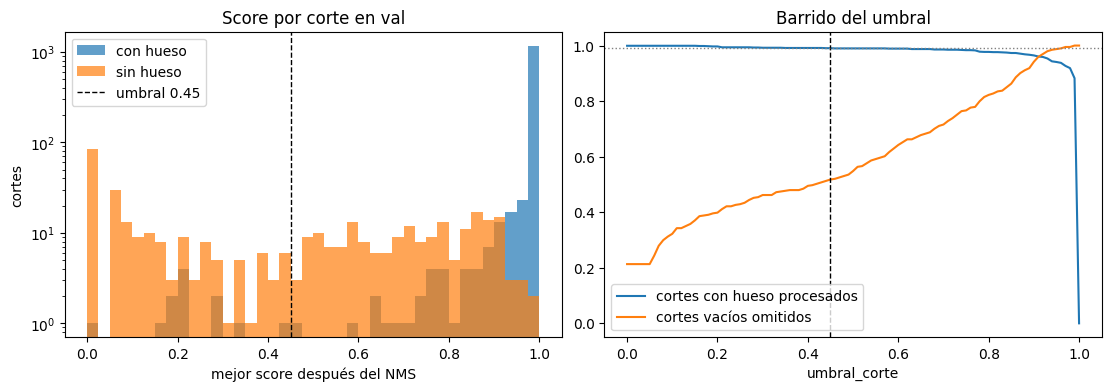

In [9]:
RECALL_MIN_HUESO = 0.99                     # fracción mínima de cortes con hueso que deben procesarse
UMBRAL_PATH = FABIAN_METRICAS_DIR / "umbral_corte.json"
UMBRAL_CORTE = None                         # sin modelo entrenado no se calibra: se procesan todos los cortes

if PESOS_ENTRENADOS:
    casos_val = sorted(df.loc[df["split"] == "val", "case_id"])
    filas_cal, t0 = [], time.time()
    for caso in casos_val:
        fila = df[df["case_id"] == caso].iloc[0]
        vol = sitk.GetArrayFromImage(sitk.ReadImage(str(resolve_repo_path(fila["image_path"])))).astype(np.float32)
        lab = sitk.GetArrayFromImage(sitk.ReadImage(str(resolve_repo_path(fila["label_path"]))))
        tiene_hueso = lab.reshape(lab.shape[0], -1).any(axis=1)      # el corte tiene algún vóxel de pelvis
        for inicio in range(0, vol.shape[0], 16):
            zs = range(inicio, min(inicio + 16, vol.shape[0]))
            x = torch.from_numpy(np.stack([np.asarray(preprocesar_corte(vol[z])[0], dtype=np.float32)
                                           for z in zs]))[:, None].to(DEVICE)
            for z, s in zip(zs, scores_por_corte(componentes, x)):
                filas_cal.append({"case_id": caso, "z": z, "tiene_hueso": bool(tiene_hueso[z]), "score_max": float(s)})
        del vol, lab
        gc.collect()
    cal = pd.DataFrame(filas_cal)
    UMBRAL_CORTE, tabla_umbral = calibrar_umbral_corte(cal["score_max"], cal["tiene_hueso"],
                                                       recall_min=RECALL_MIN_HUESO)
    elegido = tabla_umbral.set_index("umbral").loc[UMBRAL_CORTE]
    cal.to_csv(FABIAN_METRICAS_DIR / "scores_cortes_val.csv", index=False)
    tabla_umbral.to_csv(FABIAN_METRICAS_DIR / "barrido_umbral_corte_val.csv", index=False)
    UMBRAL_PATH.write_text(json.dumps({
        "umbral_corte": UMBRAL_CORTE, "recall_min_hueso": RECALL_MIN_HUESO, "calibrado_con": "val",
        "casos": casos_val, "cortes": int(len(cal)), "cortes_con_hueso": int(cal["tiene_hueso"].sum()),
        "recall_hueso": float(elegido["recall_hueso"]), "rechazo_vacios": float(elegido["rechazo_vacios"]),
        "tronco": MODELO_PATH.name}, indent=2), encoding="utf-8")

    print(f"{len(cal)} cortes de val ({int(cal['tiene_hueso'].sum())} con hueso) en {time.time() - t0:.0f} s")
    print(f"Umbral elegido: {UMBRAL_CORTE:.2f} | cortes con hueso procesados: {elegido['recall_hueso']:.1%} | "
          f"cortes vacíos omitidos: {elegido['rechazo_vacios']:.1%}")
    print("Cortes vacíos sin ninguna caja después del NMS:",
          f"{int(((cal['score_max'] == 0) & ~cal['tiene_hueso']).sum())} de {int((~cal['tiene_hueso']).sum())}")
    display(tabla_umbral[tabla_umbral["umbral"].isin([0.0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, UMBRAL_CORTE])]
            .drop_duplicates("umbral").round(3))

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
    bins = np.linspace(0, 1, 41)
    ax[0].hist(cal.loc[cal["tiene_hueso"], "score_max"], bins=bins, alpha=0.7, label="con hueso")
    ax[0].hist(cal.loc[~cal["tiene_hueso"], "score_max"], bins=bins, alpha=0.7, label="sin hueso")
    ax[0].axvline(UMBRAL_CORTE, ls="--", c="k", lw=1, label=f"umbral {UMBRAL_CORTE:.2f}")
    ax[0].set_yscale("log"); ax[0].set_xlabel("mejor score después del NMS"); ax[0].set_ylabel("cortes")
    ax[0].set_title("Score por corte en val"); ax[0].legend()
    ax[1].plot(tabla_umbral["umbral"], tabla_umbral["recall_hueso"], label="cortes con hueso procesados")
    ax[1].plot(tabla_umbral["umbral"], tabla_umbral["rechazo_vacios"], label="cortes vacíos omitidos")
    ax[1].axvline(UMBRAL_CORTE, ls="--", c="k", lw=1)
    ax[1].axhline(RECALL_MIN_HUESO, ls=":", c="gray", lw=1)
    ax[1].set_xlabel("umbral_corte"); ax[1].set_title("Barrido del umbral"); ax[1].legend()
    fig.savefig(FABIAN_FIGURAS_DIR / "filtro_cortes_val.png", dpi=150)
    plt.show()
else:
    print("Filtro de cortes sin calibrar: no hay modelo entrenado; se procesan todos los cortes.")

In [10]:
# Volumen completo de un caso de val -> pertenencia 3D -> distancias (Daniela). En CPU tarda algunos minutos.
CORRER_VOLUMEN = PESOS_ENTRENADOS and DECODER_OK and CABEZA_ENTRENADA
CASO_VOLUMEN = sorted({t["case_id"] for t in targets_nms})[0]

if CORRER_VOLUMEN:
    from src.distancias_fragmentos import measure_fragment_separations
    fila = df[df["case_id"] == CASO_VOLUMEN].iloc[0]
    img_itk = sitk.ReadImage(str(resolve_repo_path(fila["image_path"])))
    t0 = time.time()
    resultado_volumen = inferir_volumen(componentes, sitk.GetArrayFromImage(img_itk).astype(np.float32),
                                        img_itk.GetSpacing(), cfg={"umbral_corte": UMBRAL_CORTE},
                                        batch_size=8, device=DEVICE, case_id=CASO_VOLUMEN)
    cortes_vol = resultado_volumen["cortes"]
    print(f"Volumen {CASO_VOLUMEN}: {len(cortes_vol)} cortes en {time.time() - t0:.0f} s | "
          f"procesados: {int(cortes_vol['procesado'].sum())} (umbral_corte = {UMBRAL_CORTE}) | "
          f"fragmentos 3D: {len(resultado_volumen['fragmentos'])} | eventos de enlace: {len(resultado_volumen['eventos'])}")
    lab_vol = sitk.GetArrayFromImage(sitk.ReadImage(str(resolve_repo_path(fila["label_path"]))))
    con_hueso = lab_vol.reshape(lab_vol.shape[0], -1).any(axis=1)
    print(f"Cortes con hueso procesados: {int(cortes_vol['procesado'][con_hueso].sum())} de {int(con_hueso.sum())} | "
          f"cortes sin hueso procesados: {int(cortes_vol['procesado'][~con_hueso].sum())} de {int((~con_hueso).sum())} | "
          f"instancias en cortes sin hueso: {int(cortes_vol['n_instancias'][~con_hueso].sum())}")
    del lab_vol
    distancias_pred = measure_fragment_separations(
        resultado_volumen["instance_volume"], resultado_volumen["spacing_xyz"],
        case_id=CASO_VOLUMEN, region_by_id=resultado_volumen["region_by_id"])
    resultado_volumen["fragmentos"].to_csv(FABIAN_METRICAS_DIR / f"pertenencia_3d_caso_{CASO_VOLUMEN}.csv", index=False)
    resultado_volumen["cortes"].to_csv(FABIAN_METRICAS_DIR / f"cortes_caso_{CASO_VOLUMEN}.csv", index=False)
    distancias_pred.to_csv(FABIAN_METRICAS_DIR / f"distancias_predichas_caso_{CASO_VOLUMEN}.csv", index=False)
    display(resultado_volumen["fragmentos"])
    display(distancias_pred)
else:
    print("Volumen completo pendiente: requiere tronco, decoder y cabeza de pertenencia entrenados.")

<string>:42: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
<string>:47: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
<string>:197: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)


Volumen 035: 373 cortes en 111 s | procesados: 322 (umbral_corte = 0.45) | fragmentos 3D: 307 | eventos de enlace: 1456
Cortes con hueso procesados: 295 de 295 | cortes sin hueso procesados: 27 de 78 | instancias en cortes sin hueso: 86


,case_id,fragment_id,region,clase,prob_sacro,prob_coxal_izquierdo,prob_coxal_derecho,clase_enlace,conflicto_enlace,n_voxels,n_cortes
0,035,1,coxal_izquierdo,2,2.792594e-01,0.490865,0.229876,2,False,30,1
1,035,2,coxal_derecho,3,1.128402e-01,0.002489,0.884671,3,False,200,3
2,035,3,sacro,1,6.258109e-01,0.047402,0.326787,1,False,452,4
3,035,4,sacro,1,5.236534e-01,0.334228,0.142118,1,False,42,3
4,035,5,sacro,1,5.246004e-01,0.000063,0.475336,1,False,4,1
...,...,...,...,...,...,...,...,...,...,...,...
302,035,303,coxal_izquierdo,2,1.915081e-05,0.932339,0.067642,2,False,43144,29
303,035,304,coxal_izquierdo,2,4.847419e-03,0.938171,0.056982,2,False,16,1
304,035,305,coxal_izquierdo,2,1.699961e-05,0.997508,0.002475,2,False,1000,3
305,035,306,coxal_izquierdo,2,2.238680e-08,0.997949,0.002051,2,False,4376,9


,case_id,region,fragment_id,main_fragment_id,is_main,n_voxels,distance_mm
0,035,coxal_derecho,230,230,True,125134,0.000000
1,035,coxal_derecho,2,230,False,200,144.493572
2,035,coxal_derecho,6,230,False,3132,126.049818
3,035,coxal_derecho,8,230,False,940,136.395276
4,035,coxal_derecho,12,230,False,384,131.459029
...,...,...,...,...,...,...,...
302,035,sacro,294,266,False,624,17.600000
303,035,sacro,296,266,False,4,20.000000
304,035,sacro,297,266,False,360,20.000000
305,035,sacro,299,266,False,104,22.400000


## 6. Evaluación de la pertenencia

Unidad: **cada fragmento real en cada corte** de `val`. Dos modos:

- `modo="gt"`: la cabeza clasifica las máscaras reales. Aísla el error de clasificación.
- `modo="pred"`: la cabeza clasifica las instancias predichas, emparejadas con las reales por IoU ≥ 0,5 (Hungarian). Un fragmento real no emparejado queda **sin clase** y cuenta como error: no se excluye.

Se compara la cabeza contra dos reglas sin aprendizaje: la **mayoría semántica** del decoder y la **caja detectada** que contiene al fragmento. F1 macro y por clase sobre todas las instancias; AUC macro uno-contra-resto con las probabilidades de la cabeza (objetivo sugerido ≥ 0,85 en ambas). `test` solo se usa en la evaluación final con la configuración congelada.

In [11]:
if DECODER_OK:
    idx_eval = list(range(0, len(targets_nms), max(1, len(targets_nms) // 64)))[:64]
    tablas_eval = []
    for modo in ("gt", "pred"):
        partes = []
        for i in range(0, len(idx_eval), 16):
            sub = idx_eval[i:i + 16]
            partes.append(evaluar_pertenencia(componentes, torch.stack([imagenes_nms[j] for j in sub]).to(DEVICE),
                                              [targets_nms[j] for j in sub], modo=modo))
        detalle = pd.concat(partes, ignore_index=True)
        detalle.to_csv(FABIAN_METRICAS_DIR / f"pertenencia_detalle_val_{modo}.csv", index=False)
        resumen = resumen_evaluacion_pertenencia(detalle)
        resumen.insert(0, "modo", modo)
        tablas_eval.append(resumen)
    tabla_pertenencia = pd.concat(tablas_eval, ignore_index=True)
    tabla_pertenencia.insert(0, "pesos", "entrenados" if (PESOS_ENTRENADOS and CABEZA_ENTRENADA) else "SIN ENTRENAR")
    tabla_pertenencia.to_csv(FABIAN_METRICAS_DIR / "pertenencia_resumen_val.csv", index=False)
    display(tabla_pertenencia.round(3))
else:
    print("Evaluación con instancias predichas pendiente: falta el decoder entrenado (ver sección 2).")

,pesos,modo,metodo,n_instancias,n_sin_clase,exactitud,f1_macro,f1_sacro,f1_coxal_izquierdo,f1_coxal_derecho,auc_macro_ovr
0,entrenados,gt,cabeza_pertenencia,200,0,0.935,0.935,0.938,0.923,0.944,0.993
1,entrenados,gt,regla_mayoria_semantica,200,3,0.965,0.972,0.964,0.972,0.979,NaN
2,entrenados,gt,regla_caja_detectada,200,7,0.945,0.962,0.963,0.951,0.972,NaN
3,entrenados,pred,cabeza_pertenencia,200,51,0.720,0.818,0.756,0.853,0.846,0.997
4,entrenados,pred,regla_mayoria_semantica,200,51,0.745,0.846,0.778,0.885,0.875,NaN
5,entrenados,pred,regla_caja_detectada,200,53,0.735,0.839,0.764,0.885,0.866,NaN


## 7. Resultados en `val` y conclusiones (Fabián)

Modelo: `modelo_multitarea_final.pt` de Miguel (backbone `plus` + compuerta CBAM + decoder **con** skip connections; etapa C, época 7). Corrida en CPU. Muestra: 200 cortes positivos de `val` (casos 035, 037, 067, 071, 079), repartidos de forma uniforme. `test` no se usó.

**1. NMS propio por clase (sección 3).**

| | Sin NMS | Con NMS (`max_det_per_class = 1`) |
|---|---|---|
| Cajas por corte | 4,23 | 2,63 |
| Falsos positivos (IoU ≥ 0,5) | 371 | 56 |
| Cajas reales sin detectar | 37 | 41 |
| mAP@0.50 | 0,881 | 0,895 |
| mAP@[0.50:0.95] | 0,619 | 0,622 |
| IoU medio de las cajas acertadas | 0,860 | 0,855 |

- El NMS elimina el 85 % de los falsos positivos y sube el mAP; a cambio pierde 4 aciertos. Cumple los objetivos de la sección 5 (mAP@0.50 ≥ 0,65; mAP@[0.50:0.95] ≥ 0,40; IoU ≥ 0,65).
- Con `max_det_per_class = 1`, `iou_thresh` entre 0,3 y 0,7 da resultados idénticos: al conservar solo la mejor caja por clase, el umbral no llega a aplicarse.
- Sin tope por clase el mAP@0.50 apenas sube (0,896–0,897), pero los falsos positivos suben a 89–154 y se rompe la definición del target (una caja por región en cada corte). **Configuración elegida: `max_det_per_class = 1`.**
- El sacro sigue siendo la clase más difícil (AP@0.50 = 0,78 frente a 0,94 y 0,96 de los coxales): sus cajas son más pequeñas y su confianza es baja (0,38 en el corte 90 de la figura).

**2. Cabeza de pertenencia, etapa D (sección 4).** 2.000 cortes de `train` (6.689 fragmentos: 1.650 sacro, 2.503 coxal izquierdo, 2.536 coxal derecho) y 800 de `val` (2.493 fragmentos). Se reentrenó porque el tronco cambió. Mejor época: 7 → **F1 macro 0,951 y AUC macro OvR 0,993**, por encima del objetivo de 0,85; parada temprana en la época 15. La pérdida de `val` es mínima en la época 3 (0,155) y sube hasta 0,217 mientras el F1 se mantiene en ~0,95: el modelo se vuelve sobreconfiado, no peor clasificador. Por eso la selección es por F1 y no por pérdida.

**3. Pertenencia frente a reglas simples (sección 6), 200 fragmentos reales.**

| Método | Máscaras reales: exactitud / F1 | Instancias predichas: exactitud / F1 | Sin clase (reales / predichas) |
|---|---|---|---|
| Cabeza de pertenencia | 0,935 / 0,935 | 0,720 / 0,818 | 0 / 51 |
| Regla de mayoría semántica | 0,965 / 0,972 | 0,745 / 0,846 | 3 / 51 |
| Regla de la caja detectada | 0,945 / 0,962 | 0,735 / 0,839 | 7 / 53 |

- Con este checkpoint, la regla de mayoría semántica supera a la cabeza en esta muestra (6 fragmentos de 200). La cabeza clasifica el 100 % de los fragmentos y entrega probabilidades (AUC 0,993), que las reglas no tienen. Con 200 fragmentos la diferencia puede ser ruido: la comparación definitiva debe hacerse en `test`.
- Con instancias predichas, **51 de 200 fragmentos reales (25,5 %) no tienen una instancia que los empareje** (IoU ≥ 0,5); con el checkpoint anterior eran 58 (29 %). Los skips mejoran la separación, pero ningún método llega a 0,85 de F1: el cuello de botella sigue siendo separar instancias, no clasificarlas.

**4. Volumen completo (sección 5).** El caso 035 pasa de punta a punta (373 cortes en 100 s en CPU) hasta `measure_fragment_separations`, pero se obtienen **312 fragmentos 3D frente a 4 reales**, con 1.456 eventos de enlace (antes 111 y 582).

- No es solo ruido. En los 100 casos, el fragmento real más pequeño tiene 469 vóxeles. Filtrar por debajo de ese tamaño quita 186 fragmentos, pero solo el 0,9 % de los vóxeles, y **siguen quedando 126**.
- Los fragmentos grandes son trozos del mismo hueso cortados a lo largo de z (por ejemplo, el coxal derecho real de 703.725 vóxeles sale en piezas de 125.134, 123.248, 68.920 y 48.888 vóxeles, de 20 a 57 cortes cada una). El fallo principal está en el **enlace entre cortes**: los IDs por corte no se mantienen de un corte al siguiente.
- Por eso aparecen distancias de 0–2 mm (trozos del mismo hueso que se tocan) y de 60–145 mm (trozos lejanos en z). Las distancias predichas todavía no se pueden comparar con las de referencia.

**5. Filtro de cortes sin hueso (sección 5.1).** Calibrado con los 5 volúmenes completos de `val` (1.662 cortes, 1.268 con pelvis): **`umbral_corte = 0,45`**. Conserva el 99,1 % de los cortes con hueso y omite el 51,8 % de los cortes vacíos (sin filtro solo se omitía el 21,3 %, los que no tenían ninguna caja).

- Los 11 cortes con hueso que se pierden están casi todos en los bordes de la pelvis (caso 037, z = 80–88; caso 079, z = 249). La excepción es el caso 067, z = 103–106: cuatro cortes dentro de la pelvis con score de 0,16–0,20, que conviene revisar visualmente.
- Los 190 cortes vacíos que siguen pasando el filtro están **todos fuera del rango de la pelvis** (mediana: 18 cortes de distancia, máximo 67): por debajo y por encima de ella. Son otros huesos que el modelo detecta con confianza alta porque nunca vio cortes sin pelvis durante el entrenamiento. Subir el umbral no lo resuelve: con 0,90 se omitirían el 95 % de los vacíos, pero se perdería cerca del 5 % de los cortes con hueso.
- En el caso 035 se procesan 322 de 373 cortes (295 de 295 con hueso, 27 de 78 vacíos). Las instancias en cortes vacíos bajan de 99 a 86 y los fragmentos 3D de 312 a 307. **El filtro funciona, pero no era la causa principal de la sobresegmentación**: los fragmentos de más salen del enlace entre cortes dentro de la pelvis.

**Pendientes y dependencias**
- Annie y Daniela: revisar `link_slice_instances_to_volume` (criterio de IoU entre cortes vecinos y unión de trozos de la misma región que se tocan) y ajustar `center_threshold` / `min_center_distance` con `val`. Después, un filtro de tamaño 3D por debajo de 469 vóxeles, validado con los fragmentos reales pequeños.
- Fabián: filtro de cortes listo (`umbral_corte = 0,45`, guardado en `umbral_corte.json`). Repetir la sección 5 cuando cambie el enlace.
- Daniela y Miguel: agregar al manifiesto cortes **sin** pelvis (sobre todo los vecinos, por encima y por debajo) para que la detección aprenda a no ver pelvis en otros huesos. Es la solución de fondo para los cortes vacíos con score alto; requiere reentrenar.
- Hoyos: usar las predicciones después del NMS, con `class_probs`, para el mAP y el AUC finales en `test`, y comparar ahí la cabeza contra la regla de mayoría semántica.
- Ambiente: esta corrida usó `torch 2.14.1+cpu`, no el `torch 2.11.0` con CUDA de `requirements.txt`. Para medir la latencia en GPU hay que reinstalarlo.
- Pillow: `letterbox_pair` usa el parámetro `mode`, que Pillow 13 elimina; `requirements.txt` fija 11.3 y no debe actualizarse sin corregirlo.